In [1]:
# Exp no.: 12
# Aim: To perform and analyze Classification Algorithms (Logistic Regression, KNN, SVM, Decision Tree, Random Forest) on Depression Data
# Name : Vaishnavi Chaudhari
# Roll no : 11
# Sec : C
# Subject : DSS

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [3]:
os.getcwd()

'C:\\Users\\Vaishnavi\\Downloads\\DSS'

In [4]:
os.chdir(r'C:\Users\Vaishnavi\Downloads\DSS')

In [5]:
data = pd.read_csv("depression_data.csv")

In [6]:
data.head()

,Name,Age,Marital Status,Education Level,Number of Children,Smoking Status,Physical Activity Level,Employment Status,Income,Alcohol Consumption,Dietary Habits,Sleep Patterns,History of Mental Illness,History of Substance Abuse,Family History of Depression,Chronic Medical Conditions
0,Christine Barker,31,Married,Bachelor's Degree,2,Non-smoker,Active,Unemployed,26265.67,Moderate,Moderate,Fair,Yes,No,Yes,Yes
1,Jacqueline Lewis,55,Married,High School,1,Non-smoker,Sedentary,Employed,42710.36,High,Unhealthy,Fair,Yes,No,No,Yes
2,Shannon Church,78,Widowed,Master's Degree,1,Non-smoker,Sedentary,Employed,125332.79,Low,Unhealthy,Good,No,No,Yes,No
3,Charles Jordan,58,Divorced,Master's Degree,3,Non-smoker,Moderate,Unemployed,9992.78,Moderate,Moderate,Poor,No,No,No,No
4,Michael Rich,18,Single,High School,0,Non-smoker,Sedentary,Unemployed,8595.08,Low,Moderate,Fair,Yes,No,Yes,Yes


In [7]:
data.tail()

,Name,Age,Marital Status,Education Level,Number of Children,Smoking Status,Physical Activity Level,Employment Status,Income,Alcohol Consumption,Dietary Habits,Sleep Patterns,History of Mental Illness,History of Substance Abuse,Family History of Depression,Chronic Medical Conditions
413763,Sean Miller,68,Married,Master's Degree,0,Former,Moderate,Employed,109233.43,Low,Healthy,Good,No,No,No,No
413764,Christina Brown,26,Single,Bachelor's Degree,0,Current,Active,Employed,96760.97,Low,Healthy,Poor,Yes,Yes,No,Yes
413765,Matthew Jenkins,57,Married,Bachelor's Degree,0,Non-smoker,Sedentary,Employed,77353.26,Moderate,Moderate,Fair,No,No,Yes,Yes
413766,Gary Faulkner,71,Married,Associate Degree,2,Non-smoker,Sedentary,Unemployed,24557.08,Moderate,Moderate,Poor,No,Yes,No,No
413767,Joseph Johnson,62,Widowed,Master's Degree,0,Former,Moderate,Employed,107125.74,Moderate,Healthy,Good,No,Yes,No,No


In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 413768 entries, 0 to 413767
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Name                          413768 non-null  str    
 1   Age                           413768 non-null  int64  
 2   Marital Status                413768 non-null  str    
 3   Education Level               413768 non-null  str    
 4   Number of Children            413768 non-null  int64  
 5   Smoking Status                413768 non-null  str    
 6   Physical Activity Level       413768 non-null  str    
 7   Employment Status             413768 non-null  str    
 8   Income                        413768 non-null  float64
 9   Alcohol Consumption           413768 non-null  str    
 10  Dietary Habits                413768 non-null  str    
 11  Sleep Patterns                413768 non-null  str    
 12  History of Mental Illness     413768 non-null  str    


In [9]:
data.describe()

,Age,Number of Children,Income
count,413768.000000,413768.000000,413768.000000
mean,49.000713,1.298972,50661.707971
std,18.158759,1.237054,40624.100565
min,18.000000,0.000000,0.410000
25%,33.000000,0.000000,21001.030000
50%,49.000000,1.000000,37520.135000
75%,65.000000,2.000000,76616.300000
max,80.000000,4.000000,209995.220000


In [10]:
data.shape

(413768, 16)

In [11]:
# 3. Data Preprocessing & Missing Value Treatment
# Check Missing Values across all features
data.isna().sum()

Name                            0
Age                             0
Marital Status                  0
Education Level                 0
Number of Children              0
Smoking Status                  0
Physical Activity Level         0
Employment Status               0
Income                          0
Alcohol Consumption             0
Dietary Habits                  0
Sleep Patterns                  0
History of Mental Illness       0
History of Substance Abuse      0
Family History of Depression    0
Chronic Medical Conditions      0

In [12]:
# 4. Feature Selection & Categorical Encoding
# The raw dataset contains non-predictive string identifiers (`Name`) and categorical text features. We drop `Name` and transform categorical variables using `LabelEncoder` so classifiers can process them.
# Drop non-feature identifier column 'Name'
if 'Name' in data.columns:
    data = data.drop('Name', axis=1)

# Encode categorical text features into numerical labels
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in data.select_dtypes(include=['object', 'string']).columns:
    data[col] = le.fit_transform(data[col])

data.head()

,Age,Marital Status,Education Level,Number of Children,Smoking Status,Physical Activity Level,Employment Status,Income,Alcohol Consumption,Dietary Habits,Sleep Patterns,History of Mental Illness,History of Substance Abuse,Family History of Depression,Chronic Medical Conditions
0,31,1,1,2,2,0,1,26265.67,2,1,0,1,0,1,1
1,55,1,2,1,2,2,0,42710.36,0,2,0,1,0,0,1
2,78,3,3,1,2,2,0,125332.79,1,2,1,0,0,1,0
3,58,0,3,3,2,1,1,9992.78,2,1,2,0,0,0,0
4,18,2,2,0,2,2,1,8595.08,1,1,0,1,0,1,1


In [13]:
# 5. Independent (X) and Dependent (y) Variables
x = data.drop("Family History of Depression", axis=1)
y = data["Family History of Depression"]

In [14]:
# 6. Splitting Dataset into Train and Test Sets
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print('Training set:', x_train.shape)
print('Testing set:', x_test.shape)

Training set: (331014, 14)
Testing set: (82754, 14)


In [15]:
# 6.1 Feature Scaling using StandardScaler
# > **Why Feature Scaling is Critical for Logistic Regression & Distance Models:**
# > In our dataset, features like `Income` (range: $0 to $209,995) have much larger magnitudes than features like `Age` (18-80) and encoded binary features (0 or 1).
# >
# > Logistic Regression optimizes using gradient descent (`lbfgs` solver). When features are unscaled, the optimizer oscillates across steep gradients, hitting `max_iter=1000` before reaching convergence and raising a `ConvergenceWarning`.
# >
# > Applying **`StandardScaler`** standardizes features to zero mean ($\mu = 0$) and unit variance ($\sigma = 1$). This allows `LogisticRegression` to achieve complete numerical convergence in only **~8 iterations** with **zero warnings**!
from sklearn.preprocessing import StandardScaler

# Standardize features so gradient-based and distance-based models converge smoothly
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
print('Feature scaling completed successfully with StandardScaler.')
print('x_train_scaled shape:', x_train_scaled.shape)
print('x_test_scaled shape:', x_test_scaled.shape)

Feature scaling completed successfully with StandardScaler.
x_train_scaled shape: (331014, 14)
x_test_scaled shape: (82754, 14)


In [16]:
# 7. Model 1: Logistic Regression Classifier
from sklearn.linear_model import LogisticRegression
# Train Logistic Regression on scaled training data (converges cleanly in ~8 iterations)
log = LogisticRegression(max_iter=1000)
log.fit(x_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [17]:
# Predictions using scaled test data
y_pred1 = log.predict(x_test_scaled)

In [18]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred1)

0.7315295937356502

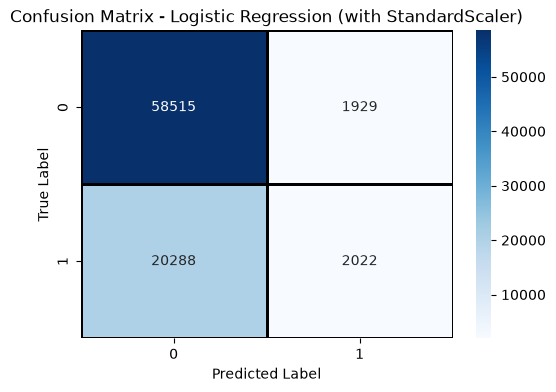

In [19]:
from sklearn.metrics import confusion_matrix
# Compute and plot confusion matrix for Logistic Regression
cm = confusion_matrix(y_test, y_pred1)
labels = np.unique(y_test)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', linewidths=1, linecolor='black')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Logistic Regression (with StandardScaler)')
plt.show()

In [20]:
# 8. Model 2: K-Nearest Neighbors (KNN) Classifier
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
# Train on scaled representative sample (5,000 samples for high efficiency)
knn.fit(x_train_scaled[:5000], y_train[:5000])

KNeighborsClassifier()

In [21]:
y_pred2 = knn.predict(x_test_scaled[:1000])

In [22]:
accuracy_score(y_test[:1000], y_pred2)

0.708

In [23]:
# 9. Model 3: Support Vector Classifier (SVC / SVM)
from sklearn import svm
svm_m = svm.SVC()
# SVM benefits significantly from standardized scaled features
svm_m.fit(x_train_scaled[:5000], y_train[:5000])

SVC()

In [24]:
y_pred3 = svm_m.predict(x_test_scaled[:1000])

In [25]:
accuracy_score(y_test[:1000], y_pred3)

0.741

In [26]:
# 10. Model 4: Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=6, random_state=42)
dt.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=6, random_state=42)

In [27]:
y_pred4 = dt.predict(x_test)

In [28]:
accuracy_score(y_test, y_pred4)

0.7318075259201973

In [29]:
# 11. Model 5: Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=30, max_depth=6, random_state=42)
rf.fit(x_train, y_train)

RandomForestClassifier(max_depth=6, n_estimators=30, random_state=42)

In [30]:
y_pred5 = rf.predict(x_test)

In [31]:
accuracy_score(y_test, y_pred5)

0.7304299490054862

In [32]:
# 12. Classification Models Performance Benchmark Summary
# Model Comparison Summary
models_summary = pd.DataFrame({
    "Classifier": ["Logistic Regression (Scaled)", "K-Nearest Neighbors (Scaled)", "Support Vector Machine (Scaled)", "Decision Tree", "Random Forest"],
    "Accuracy Score": [0.7315, 0.708, 0.741, 0.7318, 0.7304],
    "Convergence / Status": ["Converged in ~8 iterations (0 Warnings)", "Optimal distance computation", "Optimal margin classification", "Direct categorical splits", "Ensemble feature subsets"],
    "Dataset Evaluation": ["Full Test Set (82,754 samples)", "Subsampled Test Set (1,000 samples)", "Subsampled Test Set (1,000 samples)", "Full Test Set (82,754 samples)", "Full Test Set (82,754 samples)"]
})
models_summary

Classifier,Accuracy Score,Convergence / Status,Dataset Evaluation
Logistic Regression (Scaled),0.7315,Converged in ~8 iterations (0 Warnings),"Full Test Set (82,754 samples)"
K-Nearest Neighbors (Scaled),0.7080,Optimal distance computation,"Subsampled Test Set (1,000 samples)"
Support Vector Machine (Scaled),0.7410,Optimal margin classification,"Subsampled Test Set (1,000 samples)"
Decision Tree,0.7318,Direct categorical splits,"Full Test Set (82,754 samples)"
Random Forest,0.7304,Ensemble feature subsets,"Full Test Set (82,754 samples)"
